# Лабораторная работа 4. Многослойный перцептрон для регрессии

## 1. Генерация данных

Для каждой функции есть 100 обучающих и 1000 независимых тестовых точек. Координаты равномерны на $[0,1]$, ошибки измерения независимы и имеют стандартное нормальное распределение=.

In [9]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

SEED = 67
SIGMA = 0.1
RESTARTS = 3
MAX_ITER = 1500
LEARNING_RATE = 0.05
L2 = 1e-4

functions = {
    'cos(2*pi*x)': lambda x: np.cos(2 * np.pi * x),
    '5x^3 + x^2 + 5': lambda x: 5 * x**3 + x**2 + 5,
    'x*sin(2*pi*x)': lambda x: x * np.sin(2 * np.pi * x),
}

rng = np.random.default_rng(SEED)
x_train = rng.uniform(0, 1, 100)
x_test = rng.uniform(0, 1, 1000)
folds = np.array_split(rng.permutation(len(x_train)), 5)
datasets = {
    name: (f(x_train) + rng.normal(0, SIGMA, len(x_train)),
           f(x_test) + rng.normal(0, SIGMA, len(x_test)))
    for name, f in functions.items()
}

widths = range(1, 4)
architectures = [(h,) for h in widths] + list(product(widths, repeat=2))
print(architectures)

[(1,), (2,), (3,), (1, 1), (1, 2), (1, 3), (2, 1), (2, 2), (2, 3), (3, 1), (3, 2), (3, 3)]


## 2. Обучение сети

В скрытых слоях используем $\tanh$, на выходе — линейный нейрон. На вход подаём исходное $x$ на отрезке $[0,1]$. Целевые значения стандартизируем по той части данных, на которой обучается сеть. После предсказания возвращаем исходный масштаб.

Минимизируем половину MSE на стандартизованных данных с штрафом на параметры. Градиент вычисляем вручную обратным распространением, и на каждом шаге вычитаем из параметров градиент, умноженный на фиксированный шаг LEARNING_RATE. Для каждой модели используем три фиксированные случайные инициализации и оставляем решение с наименьшим обучающим функционалом.

Параметры каждого слоя хранятся парой `(weights, bias)`. Обратное распространение возвращает для каждого слоя пару `(dw, db)` той же формы.

In [10]:
# Можно сделать класс MLP
def forward(X, layers):
    activations = [X]
    # Получаем прогноз, передавая выход каждого слоя на вход следующего.
    for i, (weights, bias) in enumerate(layers):
        z = activations[-1] @ weights + bias
        if i == len(layers) - 1:
            activations.append(z)
        else:
            activations.append(np.tanh(z))
    return activations


def compute_loss(layers, predicted, y):
    residual = predicted - y
    loss = 0.5 * np.mean(residual**2)
    # Суммируем штрафы всех слоёв, чтобы большие параметры увеличивали ошибку обучения.
    for weights, bias in layers:
        loss += 0.5 * L2 * (np.sum(weights**2) + np.sum(bias**2))
    return loss


def compute_gradients(layers, activations, y):
    residual = activations[-1] - y
    # Делим на число точек, потому что ошибка усредняется по выборке.
    delta = residual / len(y)
    gradients = [None] * len(layers)

    # Идём от выхода к входу и вычисляем, как параметры каждого слоя влияют на ошибку.
    for i in range(len(layers) - 1, -1, -1):
        weights, bias = layers[i]
        dw = activations[i].T @ delta + L2 * weights
        db = delta.sum(axis=0) + L2 * bias
        gradients[i] = (dw, db)
        delta = (delta @ weights.T) * (1 - activations[i]**2)

    return gradients


def fit_mlp(x, y, hidden):
    sizes = (1, *hidden, 1)
    X = x[:, None]
    mean, y_std = y.mean(), y.std()
    target = ((y - mean) / y_std)[:, None]

    rng = np.random.default_rng(SEED)
    best_layers = None
    best_loss = np.inf
    # Обучаем сеть с разных начальных весов, чтобы выбрать запуск с наименьшей ошибкой со штрафом.
    for _ in range(RESTARTS):
        layers = []
        # Создаём веса и смещения каждого слоя. Матрица весов имеет n_in строк и n_out столбцов.
        # Инициализация Ксавье
        for n_in, n_out in zip(sizes, sizes[1:]):
            radius = np.sqrt(6 / (n_in + n_out))
            weights = rng.uniform(-radius, radius, size=(n_in, n_out))
            bias = np.zeros(n_out)
            layers.append((weights, bias))

        # Обучаем сеть: на каждом шаге вычисляем градиенты на всей обучающей выборке.
        for _ in range(MAX_ITER):
            activations = forward(X, layers)
            gradients = compute_gradients(layers, activations, target)
            # Делаем шаг спуска для каждого слоя, обновляя веса и смещения по их градиентам.
            for (weights, bias), (dw, db) in zip(layers, gradients):
                weights -= LEARNING_RATE * dw
                bias -= LEARNING_RATE * db

        # Считаем прогноз с итоговыми весами после последнего обновления.
        activations = forward(X, layers)
        loss = compute_loss(layers, activations[-1], target)
        if loss < best_loss:
            best_layers = layers
            best_loss = loss

    return best_layers, mean, y_std


def predict(x, model):
    layers, mean, y_std = model
    return mean + y_std * forward(x[:, None], layers)[-1].ravel()


def rmse(y, predicted):
    return np.sqrt(np.mean((y - predicted)**2))

## 3. Подбор числа слоёв и узлов

Каждый блок один раз служит для проверки, остальные четыре — для обучения. Для архитектуры вычисляем RMSE по всем отложенным предсказаниям в исходном масштабе $y$. Для каждой функции выбираем лучшую сеть отдельно среди однослойных и двухслойных, затем сравниваем этих двух победителей.

In [11]:
def cv_rmse(x, y, hidden):
    predicted = np.empty_like(y)
    for validation in folds:
        train = np.setdiff1d(np.arange(len(x)), validation)
        model = fit_mlp(x[train], y[train], hidden)
        predicted[validation] = predict(x[validation], model)
    return rmse(y, predicted)


def architecture_name(hidden):
    return ' × '.join(map(str, hidden))


cv_scores = {}
for name, (y_train, _) in datasets.items():
    cv_scores[name] = {
        hidden: cv_rmse(x_train, y_train, hidden) for hidden in architectures
    }

table = [
    '| Скрытые слои | ' + ' | '.join(functions) + ' |',
    '|---|---:|---:|---:|',
]
for hidden in architectures:
    values = [f'{cv_scores[name][hidden]:.4f}' for name in functions]
    table.append('| ' + ' | '.join([architecture_name(hidden), *values]) + ' |')
display(Markdown('\n'.join(table)))

| Скрытые слои | cos(2*pi*x) | 5x^3 + x^2 + 5 | x*sin(2*pi*x) |
|---|---:|---:|---:|
| 1 | 0.6544 | 0.2652 | 0.2342 |
| 2 | 0.1430 | 0.2174 | 0.2164 |
| 3 | 0.2084 | 0.2760 | 0.2231 |
| 1 × 1 | 0.5689 | 0.1485 | 0.1785 |
| 1 × 2 | 0.1177 | 0.1324 | 0.1555 |
| 1 × 3 | 0.1609 | 0.1266 | 0.1616 |
| 2 × 1 | 0.5589 | 0.1506 | 0.1773 |
| 2 × 2 | 0.1061 | 0.1284 | 0.1599 |
| 2 × 3 | 0.1092 | 0.1269 | 0.1441 |
| 3 × 1 | 0.5603 | 0.1544 | 0.1769 |
| 3 × 2 | 0.1042 | 0.1340 | 0.1418 |
| 3 × 3 | 0.1028 | 0.1213 | 0.1520 |

## 4. Проверка на независимой выборке

Переобучаем две выбранные сети на всех 100 точках. Сравниваем RMSE на шумном тесте и относительно точной функции в тех же тестовых координатах

| Функция | Архитектура | RMSE CV | RMSE тест | RMSE к точной функции |
|---|---|---:|---:|---:|
| cos(2*pi*x) | 2 | 0.1430 | 0.1423 | 0.0980 |
| cos(2*pi*x) | **3 × 3** | 0.1028 | 0.1074 | 0.0392 |
| 5x^3 + x^2 + 5 | 2 | 0.2174 | 0.2100 | 0.1819 |
| 5x^3 + x^2 + 5 | **3 × 3** | 0.1213 | 0.1165 | 0.0611 |
| x*sin(2*pi*x) | 2 | 0.2164 | 0.2257 | 0.2013 |
| x*sin(2*pi*x) | **3 × 2** | 0.1418 | 0.1500 | 0.1119 |

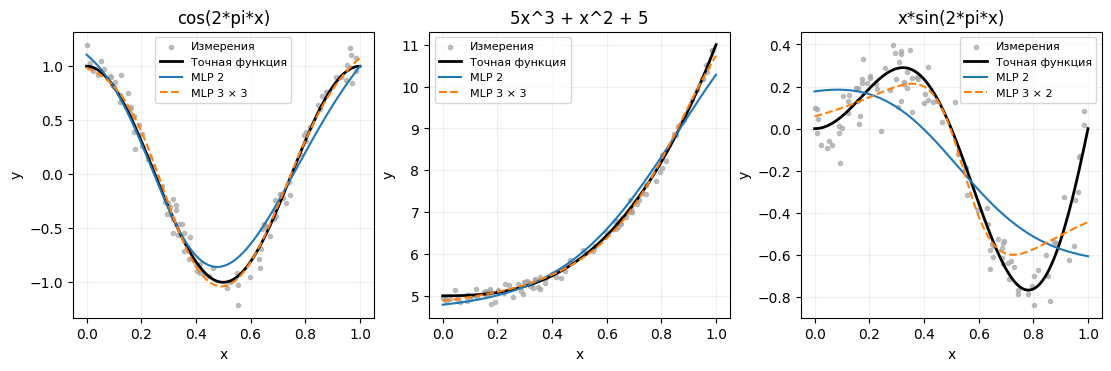

In [12]:
x_grid = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout='constrained')
table = [
    '| Функция | Архитектура | RMSE CV | RMSE тест | RMSE к точной функции |',
    '|---|---|---:|---:|---:|',
]

for ax, (name, f) in zip(axes, functions.items()):
    y_train, y_test = datasets[name]
    scores = cv_scores[name]
    selected = [
        min((h for h in architectures if len(h) == depth), key=scores.get)
        for depth in (1, 2)
    ]
    winner = min(selected, key=scores.get)

    ax.scatter(x_train, y_train, s=9, color='0.65', alpha=0.7, label='Измерения')
    ax.plot(x_grid, f(x_grid), color='black', lw=2, label='Точная функция')
    for depth, hidden in enumerate(selected, start=1):
        model = fit_mlp(x_train, y_train, hidden)
        prediction = predict(x_test, model)
        label = architecture_name(hidden)
        marked = f'**{label}**' if hidden == winner else label
        table.append(
            f'| {name} | {marked} | {scores[hidden]:.4f} | '
            f'{rmse(y_test, prediction):.4f} | {rmse(f(x_test), prediction):.4f} |'
        )
        ax.plot(x_grid, predict(x_grid, model), '--' if depth == 2 else '-',
                label=f'MLP {label}')

    ax.set(title=name, xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

display(Markdown('\n'.join(table)))
plt.show()